# Vector Spaces, Projections, and Least Squares

**AI Mathematics · 1. Linear Algebra**

Connect linear independence and subspaces to projection, orthogonalization, and least-squares fitting.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Interpret span, basis, dimension, and linear independence.
- Project a vector onto a subspace.
- Use Gram-Schmidt and least squares safely.

In [1]:
import numpy as np

## 1. Span, basis, and dimension
The span of a set of vectors contains every linear combination of them. A basis is a linearly independent set that spans a space. The number of vectors in a basis is the dimension. The columns of a matrix span its column space; its rows span its row space.

In [2]:
import numpy as np

A = np.array([[1.0, 2.0, 3.0], [2.0, 4.0, 6.0]])
print("shape:", A.shape)
print("rank:", np.linalg.matrix_rank(A))
print("column-space dimension:", np.linalg.matrix_rank(A))
print("row-space dimension:", np.linalg.matrix_rank(A))

shape: (2, 3)
rank: 1
column-space dimension: 1
row-space dimension: 1


## 2. Orthogonal projection onto one vector
The projection of \(v\) onto a nonzero vector \(u\) is \(\operatorname{proj}_u(v)=\frac{v^T u}{u^T u}u\). The residual \(v-\operatorname{proj}_u(v)\) is orthogonal to \(u\), up to floating-point error.

In [3]:
v = np.array([3.0, 1.0])
u = np.array([1.0, 2.0])
projection = (v @ u) / (u @ u) * u
residual = v - projection
print("projection:", projection)
print("residual:", residual)
print("residual dot u:", residual @ u)

projection: [1. 2.]
residual: [ 2. -1.]
residual dot u: 0.0


## 3. Projection onto a column space
If the columns of \(Q\) are orthonormal, projection onto their span is \(QQ^Tv\). If they are not orthonormal, do not use this formula directly; QR factorization or a least-squares solve is safer.

In [4]:
Q = np.array([[1.0, 0.0], [0.0, 1.0], [0.0, 0.0]])
v = np.array([2.0, -1.0, 5.0])
projected = Q @ (Q.T @ v)
print("projected:", projected)
print("residual:", v - projected)

projected: [ 2. -1.  0.]
residual: [0. 0. 5.]


## 4. Gram-Schmidt orthogonalization
Gram-Schmidt converts independent vectors into an orthonormal basis. In production numerical algorithms, QR factorization is often preferred because classical Gram-Schmidt can lose orthogonality when vectors are nearly dependent.

In [5]:
def gram_schmidt(vectors, tol=1e-12):
    basis = []
    for vector in vectors:
        vector = np.asarray(vector, dtype=float)
        for q in basis:
            vector = vector - np.dot(q, vector) * q
        norm = np.linalg.norm(vector)
        if norm < tol:
            raise ValueError("Input vectors are linearly dependent or nearly dependent")
        basis.append(vector / norm)
    return np.vstack(basis)

V = [np.array([1.0, 1.0, 0.0]), np.array([1.0, 0.0, 1.0])]
Q = gram_schmidt(V)
print(Q)
print("Q Q^T:\n", Q @ Q.T)

[[ 0.70710678  0.70710678  0.        ]
 [ 0.40824829 -0.40824829  0.81649658]]
Q Q^T:
 [[1.00000000e+00 1.03018891e-16]
 [1.03018891e-16 1.00000000e+00]]


## 5. Least squares
For inconsistent equations \(Ax=b\), least squares minimizes \(\|Ax-b\|_2^2\). The residual is orthogonal to the column space of \(A\). This is the foundation of ordinary least-squares regression.

In [6]:
X = np.array([[1.0, 0.0], [1.0, 1.0], [1.0, 2.0], [1.0, 3.0]])
y = np.array([1.0, 1.8, 3.2, 3.9])
beta, *_ = np.linalg.lstsq(X, y, rcond=None)
residual = y - X @ beta
print("coefficients:", beta)
print("residual orthogonality check:", X.T @ residual)

coefficients: [0.96 1.01]
residual orthogonality check: [1.55431223e-15 8.88178420e-16]


### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Visual lab: projection, residual, and least squares

Projecting a vector onto a line separates it into a component that lies along the line and a residual perpendicular to it. This is the geometric idea behind least squares: choose a model whose predictions are the closest projection of the observations onto the model's column space.

dot(projection residual, line direction): 0.0


03_vector_spaces_projections.ipynb:cell15:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


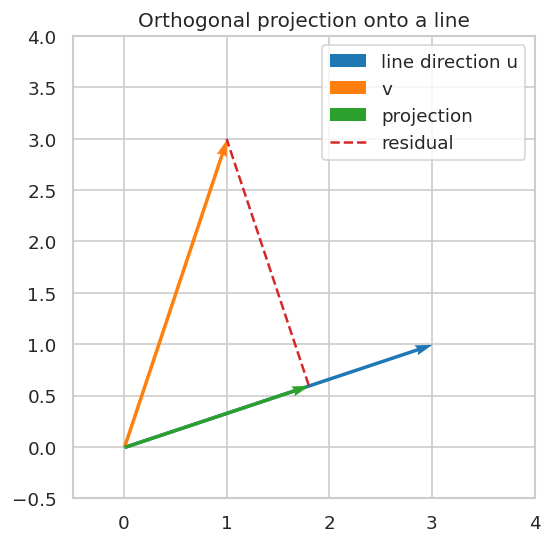

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_proj_u = np.array([3.0, 1.0])
viz_proj_v = np.array([1.0, 3.0])
viz_proj = (viz_proj_v @ viz_proj_u / (viz_proj_u @ viz_proj_u)) * viz_proj_u
viz_resid = viz_proj_v - viz_proj
fig, ax = plt.subplots(figsize=(6, 5))
for vec, label, color in [(viz_proj_u, "line direction u", "tab:blue"), (viz_proj_v, "v", "tab:orange"), (viz_proj, "projection", "tab:green")]:
    ax.quiver(0, 0, vec[0], vec[1], angles="xy", scale_units="xy", scale=1, color=color, label=label)
ax.plot([viz_proj[0], viz_proj_v[0]], [viz_proj[1], viz_proj_v[1]], "--", color="tab:red", label="residual")
ax.set_xlim(-0.5, 4); ax.set_ylim(-0.5, 4); ax.set_aspect("equal", adjustable="box")
ax.legend(); ax.set_title("Orthogonal projection onto a line"); plt.show()
print("dot(projection residual, line direction):", round(float(viz_resid @ viz_proj_u), 10))

### Least-squares line fit with NumPy and a tidy data table

`np.linalg.lstsq` finds the coefficients that minimize the sum of squared residuals. The line below is a compact example of supervised regression. The fitted line summarizes the trend; it does not imply that the relationship is causal.

sum of squared residuals: 27.25213280412911


03_vector_spaces_projections.ipynb:cell17:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,x,observed y,fitted y,residual
0,1.0,4.83,3.28,1.55
1,2.0,6.13,5.23,0.89
2,3.0,7.51,7.19,0.32
3,4.0,5.92,9.15,-3.22
4,5.0,11.85,11.10,0.74
5,6.0,9.81,13.06,-3.25
6,7.0,16.16,15.02,1.15
7,8.0,17.51,16.97,0.54
8,9.0,19.65,18.93,0.72
9,10.0,21.44,20.88,0.56


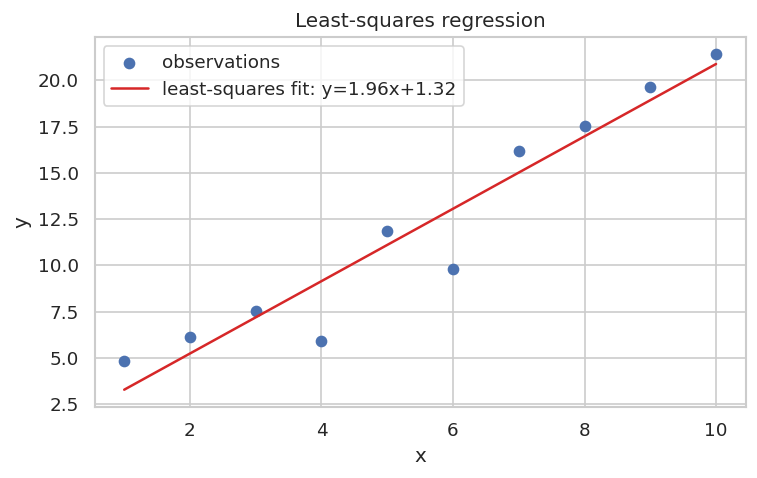

In [8]:
viz_ls_rng = np.random.default_rng(23)
viz_ls_x = np.arange(1, 11, dtype=float)
viz_ls_y = 1.8 * viz_ls_x + 2.2 + viz_ls_rng.normal(0, 1.5, size=viz_ls_x.size)
viz_ls_design = np.column_stack([np.ones_like(viz_ls_x), viz_ls_x])
viz_ls_coef, viz_ls_residuals, viz_ls_rank, viz_ls_singular = np.linalg.lstsq(viz_ls_design, viz_ls_y, rcond=None)
viz_ls_pred = viz_ls_design @ viz_ls_coef
viz_ls_df = pd.DataFrame({"x": viz_ls_x, "observed y": viz_ls_y, "fitted y": viz_ls_pred, "residual": viz_ls_y-viz_ls_pred})
display(viz_ls_df.round(2))
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(viz_ls_x, viz_ls_y, label="observations")
ax.plot(viz_ls_x, viz_ls_pred, color="tab:red", label=f"least-squares fit: y={viz_ls_coef[1]:.2f}x+{viz_ls_coef[0]:.2f}")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(); ax.set_title("Least-squares regression"); plt.show()
print("sum of squared residuals:", np.sum((viz_ls_y-viz_ls_pred)**2))

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Project [2, 3] onto [1, 0].

In [9]:
v = np.array([2.0, 3.0]); u = np.array([1.0, 0.0])
print((v @ u) / (u @ u) * u)

[2. 0.]


### Exercise 2
Exercise 2: Use QR to obtain an orthonormal basis for the columns of a matrix.

In [10]:
A = np.array([[1.0, 1.0], [1.0, 0.0], [0.0, 1.0]])
Q, R = np.linalg.qr(A)
print("Q^T Q:\n", Q.T @ Q)

Q^T Q:
 [[1.00000000e+00 6.35145629e-17]
 [6.35145629e-17 1.00000000e+00]]


## Key takeaways
- Rank gives the dimension of the row and column spaces.
- Projection separates a vector into an in-subspace component and an orthogonal residual.
- Least squares is useful when equations are noisy or overdetermined.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.